# Overview
- MNIST dataset
  + Goal: recognizing handwritten digits
  + Input: a 28x28 image
  + Output: class label (0, 1,..., 9)
- Defining an CNN+MLP for MNIST
- Training and evaluating an CNN+MLP

# Import libraries

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets

import time
import numpy as np
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

device: cuda


In [3]:
num_classes = 10   # 10 classes: 0, 1,..., 9

# (1) Data

In [4]:
# the data, shuffled and split between train and test sets
train_set = datasets.MNIST(root='./data', train=True, download=True)
test_set = datasets.MNIST(root='./data', train=False, download=True)
(x_train, y_train), (x_test, y_test) = (train_set.data.numpy(), train_set.targets.numpy()), \
                                       (test_set.data.numpy(), test_set.targets.numpy())

# PyTorch uses channels-first layout: (N, C, H, W)
x_train = x_train.reshape(60000, 1, 28, 28)
x_test = x_test.reshape(10000, 1, 28, 28)
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
x_train /= 255
x_test /= 255
print(x_train.shape[0], 'train samples')
print(x_test.shape[0], 'test samples')

# nn.CrossEntropyLoss expects class indices (0, 1,..., 9), not one-hot vectors,
# so the labels are kept as integer class vectors
y_train = y_train.astype('int64')
y_test = y_test.astype('int64')

100%|██████████| 9.91M/9.91M [00:05<00:00, 1.78MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 89.7kB/s]
100%|██████████| 1.65M/1.65M [00:04<00:00, 343kB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.47MB/s]

60000 train samples
10000 test samples


In [5]:
#   [0, 1, 2]
# 0  1  0  0
# 1  0  1  0
# 2  0  0  1
# (one-hot encoding is shown for illustration; nn.CrossEntropyLoss works directly with class indices)
F.one_hot(torch.tensor(2), num_classes = 3)

tensor([0, 0, 1])

# (2) Declare model

In [6]:
class MnistCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        # 28x28 MNIST image, input shape (N, 1, 28, 28)

        # conv, pooling layers + dropout
        self.conv1 = nn.Sequential(nn.Conv2d(1, 64, kernel_size=3, padding=1), nn.ReLU())     # 'same' padding
        self.pool1 = nn.MaxPool2d(kernel_size=2)
        self.conv_dropout1 = nn.Dropout(p=0.2)

        self.conv2 = nn.Sequential(nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU())
        self.pool2 = nn.MaxPool2d(kernel_size=2)
        self.conv_dropout2 = nn.Dropout(p=0.2)

        self.conv3 = nn.Sequential(nn.Conv2d(128, 256, kernel_size=3, padding=1), nn.ReLU())
        self.pool3 = nn.MaxPool2d(kernel_size=2)
        self.conv_dropout3 = nn.Dropout(p=0.2)

        # similar to the MLP example!
        # matrix ---> vector  (28 -> 14 -> 7 -> 3, so 256 x 3 x 3 features)
        self.flatten = nn.Flatten()

        # FC layers + dropout
        self.fc1 = nn.Sequential(nn.Linear(256 * 3 * 3, 512), nn.ReLU())
        self.fc_dropout1 = nn.Dropout(p=0.2)

        self.fc2 = nn.Sequential(nn.Linear(512, 512), nn.ReLU())
        self.fc_dropout2 = nn.Dropout(p=0.2)

        # 'fc3_10ways_softmax': outputs raw logits, softmax is applied inside nn.CrossEntropyLoss
        self.fc3 = nn.Linear(512, num_classes)

        # Keras default initialization: glorot_uniform weights, zero biases
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.xavier_uniform_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.conv_dropout1(self.pool1(self.conv1(x)))
        x = self.conv_dropout2(self.pool2(self.conv2(x)))
        x = self.conv_dropout3(self.pool3(self.conv3(x)))
        x = self.flatten(x)
        x = self.fc_dropout1(self.fc1(x))
        x = self.fc_dropout2(self.fc2(x))
        return self.fc3(x)


# define model
model = MnistCNN(num_classes).to(device)

# print model summary
print(model)
print('Total params: {:,}'.format(sum(p.numel() for p in model.parameters())))
print('Trainable params: {:,}'.format(sum(p.numel() for p in model.parameters() if p.requires_grad)))

MnistCNN(
  (conv1): Sequential(
    (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv_dropout1): Dropout(p=0.2, inplace=False)
  (conv2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
  )
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv_dropout2): Dropout(p=0.2, inplace=False)
  (conv3): Sequential(
    (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
  )
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv_dropout3): Dropout(p=0.2, inplace=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Sequential(
    (0): Linear(in_features=2304, out_features=512, bias=True)
    (1): ReLU()
  )
  (fc_dropout1): Dropout(p=0.2, inplace=False)
  (fc2): Sequential(
    (0): Li

In [7]:
# visualize model architecture (replacement for keras plot_model)
print(model)

MnistCNN(
  (conv1): Sequential(
    (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv_dropout1): Dropout(p=0.2, inplace=False)
  (conv2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
  )
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv_dropout2): Dropout(p=0.2, inplace=False)
  (conv3): Sequential(
    (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
  )
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv_dropout3): Dropout(p=0.2, inplace=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Sequential(
    (0): Linear(in_features=2304, out_features=512, bias=True)
    (1): ReLU()
  )
  (fc_dropout1): Dropout(p=0.2, inplace=False)
  (fc2): Sequential(
    (0): Li

# (3) Train defined model
- Note that the training history including loss and accuracy will be save in 'history' variable
- In case your system runs out of memory (OOM), try to decrease batch size

In [8]:
# helper functions replacing Keras' model.fit / model.evaluate / model.predict
def fit(model, train_loader, val_loader, epochs, optimizer, criterion):
    history = {'loss': [], 'acc': [], 'val_loss': [], 'val_acc': []}
    for epoch in range(epochs):
        model.train()
        total_loss, total_correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            out = model(xb)
            loss = criterion(out, yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * xb.size(0)
            total_correct += (out.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        val_loss, val_acc = evaluate(model, val_loader, criterion)
        history['loss'].append(total_loss / total)
        history['acc'].append(total_correct / total)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        print('Epoch %d/%d - loss: %.4f - acc: %.4f - val_loss: %.4f - val_acc: %.4f'
              % (epoch + 1, epochs, history['loss'][-1], history['acc'][-1], val_loss, val_acc))
    return history


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, total_correct, total = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        total_loss += criterion(out, yb).item() * xb.size(0)
        total_correct += (out.argmax(dim=1) == yb).sum().item()
        total += xb.size(0)
    return total_loss / total, total_correct / total


@torch.no_grad()
def predict(model, x, batch_size=128):
    """Run the model on a numpy array and return the outputs as a numpy array."""
    model.eval()
    outputs = []
    for i in range(0, len(x), batch_size):
        xb = torch.as_tensor(x[i:i + batch_size], dtype=torch.float32).to(device)
        outputs.append(model(xb).cpu())
    return torch.cat(outputs).numpy()

In [9]:
# declare learning rate, loss function, and model metric
criterion = nn.CrossEntropyLoss()   # categorical cross-entropy (softmax + negative log-likelihood)
lr = 0.01
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

# train the model
batch_size = 128
epochs = 30

train_loader = DataLoader(TensorDataset(torch.from_numpy(x_train), torch.from_numpy(y_train)),
                          batch_size=batch_size, shuffle=True)
test_loader = DataLoader(TensorDataset(torch.from_numpy(x_test), torch.from_numpy(y_test)),
                         batch_size=batch_size, shuffle=False)

starting_time = time.time()
history = fit(model, train_loader, test_loader, epochs, optimizer, criterion)
print('> training time is %.4f minutes' % ((time.time() - starting_time)/60))

Epoch 1/30 - loss: 2.1970 - acc: 0.2475 - val_loss: 1.5560 - val_acc: 0.6635
Epoch 2/30 - loss: 0.9002 - acc: 0.6998 - val_loss: 0.3313 - val_acc: 0.9069
Epoch 3/30 - loss: 0.4158 - acc: 0.8666 - val_loss: 0.1865 - val_acc: 0.9450
Epoch 4/30 - loss: 0.2806 - acc: 0.9106 - val_loss: 0.1393 - val_acc: 0.9557
Epoch 5/30 - loss: 0.2265 - acc: 0.9292 - val_loss: 0.1210 - val_acc: 0.9609
Epoch 6/30 - loss: 0.1949 - acc: 0.9383 - val_loss: 0.1016 - val_acc: 0.9657
Epoch 7/30 - loss: 0.1718 - acc: 0.9465 - val_loss: 0.0905 - val_acc: 0.9692
Epoch 8/30 - loss: 0.1560 - acc: 0.9507 - val_loss: 0.0829 - val_acc: 0.9736
Epoch 9/30 - loss: 0.1426 - acc: 0.9557 - val_loss: 0.0754 - val_acc: 0.9734
Epoch 10/30 - loss: 0.1342 - acc: 0.9572 - val_loss: 0.0709 - val_acc: 0.9753
Epoch 11/30 - loss: 0.1246 - acc: 0.9604 - val_loss: 0.0670 - val_acc: 0.9773
Epoch 12/30 - loss: 0.1186 - acc: 0.9628 - val_loss: 0.0603 - val_acc: 0.9798
Epoch 13/30 - loss: 0.1137 - acc: 0.9646 - val_loss: 0.0576 - val_acc: 0.

### Training time
- Training time with GTX 1080 is about 4.3095 minutes for 30 epochs (measured with the original Keras version)
- Training time with Core i7 is around 105.5 minutes for 30 epochs (measured with the original Keras version)

In [10]:
score = evaluate(model, test_loader, criterion)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

Test loss: 0.033686569061037154
Test accuracy: 0.988


In [11]:
x_train.shape, y_train.shape

((60000, 1, 28, 28), (60000,))

In [12]:
data_org = x_train.reshape(x_train.shape[0], -1)
data_lbl = y_train   # labels are already class indices
print(data_org.shape, data_lbl.shape)

(60000, 784) (60000,)


In [14]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
org_pca = pca.fit_transform(data_org)

In [15]:
print(org_pca.shape)

(60000, 2)


In [16]:
# access a layer by its attribute name (Keras: model.get_layer('fc2'))
model.fc2

Sequential(
  (0): Linear(in_features=512, out_features=512, bias=True)
  (1): ReLU()
)

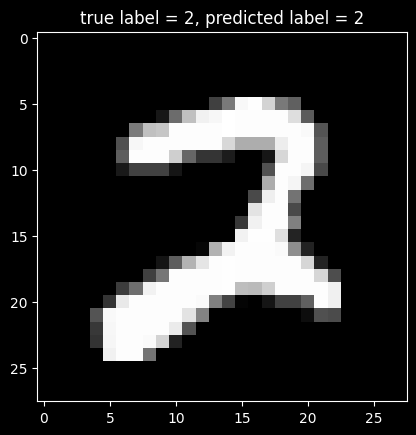

In [17]:
# select a test image randomly
random_test_index = np.random.choice(x_test.shape[0], size=1)[0]
test_img = x_test[random_test_index]
test_label = y_test[random_test_index]

# predict test image with trained model (softmax turns the logits into class probabilities)
pred_label = F.softmax(torch.from_numpy(predict(model, np.expand_dims(test_img, axis=0))), dim=1).numpy()
pred_label = np.argmax(pred_label)

plt.imshow(test_img[0, :, :], cmap='gray')
plt.title('true label = %d, predicted label = %d' % (test_label, pred_label))
plt.show()

In [18]:
class FeatureExtractor(nn.Module):
    """Returns the output of an intermediate layer of `model` (captured with a forward hook)."""
    def __init__(self, model, layer):
        super().__init__()
        self.model = model
        self.layer = layer

    def forward(self, x):
        features = {}
        handle = self.layer.register_forward_hook(lambda module, inp, out: features.update(out=out))
        try:
            self.model(x)
        finally:
            handle.remove()
        return features['out']


model_fc2 = FeatureExtractor(model, model.fc2)

In [19]:
y_feat = predict(model_fc2, x_train)

In [20]:
print(y_feat.shape)

(60000, 512)


In [21]:
from sklearn.decomposition import PCA
pca_fc2 = PCA(n_components=2)
fc2_pca = pca_fc2.fit_transform(y_feat)

In [22]:
print(fc2_pca.shape)

(60000, 2)


In [23]:
# output of 'pool3' followed by global average pooling (N, 256, 3, 3) -> (N, 256)
x1 = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten())   # GlobalAveragePooling2D

In [24]:
model2 = nn.Sequential(FeatureExtractor(model, model.pool3), x1)

In [25]:
y2_feat = predict(model2, x_train)

In [26]:
print(y2_feat.shape)

(60000, 256)


In [27]:
from sklearn.decomposition import PCA
pca_y2 = PCA(n_components=2)
y2_pca = pca_y2.fit_transform(y2_feat)

Text(0.5, 1.0, 'Visualization of MNIST dataset using PCA')

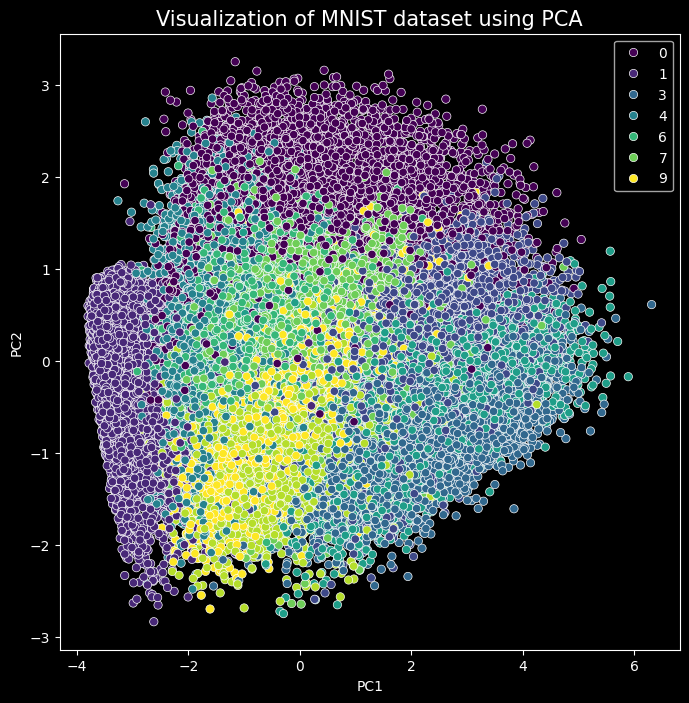

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 8))
sns.scatterplot(x=y2_pca[:, 0], y=y2_pca[:, 1], hue=data_lbl, palette='viridis')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Visualization of MNIST dataset using PCA', {'fontsize': 15})